# Section 2 · Visualize quantum circuits, measurements, and states

Exam weight: 11% of C1000-179 · about 7 of the 68 questions

## Study path

**Core first pass:** Read circuit and dynamic-circuit drawings, measurement histograms, Bloch vectors and Q-spheres; recognise the other state plots and backend/layout plots.

- Core coding practice: **2.1–2.6**.
- Optional second pass: **2.7 (compute three-qubit Bloch vectors); the marked style, sorting-error and exact decomposition-count questions.**
- Core review: answer all questions without an optional label.

Run the setup cell, then work through the unmarked examples in order. Complete a practice starter before running its check cell. At an optional block, use its **continue with the core path** link to skip the entire block; the remaining core cells do not depend on it. Notebook tags `study-core` and `study-optional` also identify the two paths; ordinary **Run All** does not filter tags.

Core/optional labels set a learning priority, not a boundary on what the exam may ask. The [official objectives and sample](https://www.ibm.com/training/certification/ibm-certified-quantum-computation-using-qiskit-v2x-developer-associate-C9008400) remain the coverage reference.

**Jump to:** [Circuit drawings](#s2-core-2) · [Measurements](#s2-core-42) · [State plots](#s2-core-68) · [Review](#s2-core-95)

Official objectives
- 2.1 Visualize quantum circuits
- 2.2 Visualize quantum measurements
- 2.3 Visualize quantum states

Topics
- pick the right `QuantumCircuit.draw()` output (`"text"`, `"mpl"`, `"latex"`, `"latex_source"`) and predict what `reverse_bits`, `fold`, `idle_wires`, `initial_state`, `plot_barriers`, `justify`, `cregbundle` and `style` change;
- read diagrams of composite gates (with `decompose()`), dynamic circuits (`if_test` / `if_else` blocks) and transpiled circuits that carry a layout;
- plot counts with `plot_histogram` and `plot_distribution`, compare several runs, and read little-endian bitstrings on the x axis;
- choose between Bloch, Q-sphere, city, Hinton and Pauli-vector plots, and go from a plot to a state and back;
- recognise the backend plots `plot_gate_map`, `plot_coupling_map`, `plot_circuit_layout` and `plot_error_map`.

Built from the Qiskit Advocate KR study notebooks `1_Visualize_Quantum_Circuits`, `2_Visualize_Quantum_Measurements` and `3_Visualize_Quantum_States_ko` and the QAMP 2025 tutorial (links in the Sources cell at the end).

How to use it: follow the core path above first, running the selected cells in order. In each selected practice cell replace the `None` / `# TODO` parts, then run its check cell. Solutions and answers are folded right under each question. For all plots in this section install the extras with `pip install "qiskit[visualization]"` (matplotlib, pylatexenc, seaborn, sympy, Pillow, pydot). The device plots (`plot_gate_map`, `plot_circuit_layout`, ...) also need the Graphviz system package (`dot`, e.g. `brew install graphviz` or `sudo apt install graphviz`; the pip package `graphviz` is not enough), and `qc.draw("latex")` needs a LaTeX installation. The cells that use Graphviz, sympy or LaTeX are guarded, so the notebook still runs if one of them is missing.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import QFTGate
from qiskit.quantum_info import Statevector, DensityMatrix, Pauli, partial_trace
from qiskit_aer import AerSimulator
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.exceptions import MissingOptionalLibraryError
from qiskit.utils.optionals import HAS_GRAPHVIZ, HAS_PDFLATEX, HAS_SYMPY
from qiskit.visualization import (
    circuit_drawer, plot_histogram, plot_distribution,
    plot_bloch_vector, plot_bloch_multivector, plot_state_qsphere,
    plot_state_city, plot_state_hinton, plot_state_paulivec,
    plot_gate_map, plot_coupling_map, plot_circuit_layout, plot_error_map,
)
from qiskit_ibm_runtime import SamplerV2, EstimatorV2
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

plt.rcParams["figure.dpi"] = 72          # modest resolution keeps the notebook small


def tidy(d, nd=3):
    """Plain str keys and rounded values (NumPy 2 would print np.str_ / np.float64)."""
    out = {}
    for k, v in d.items():
        v = complex(v)
        out[str(k)] = round(v.real, nd) if abs(v.imag) < 1e-12 else complex(round(v.real, nd), round(v.imag, nd))
    return out


print(f"qiskit {qiskit.__version__} | qiskit-aer {qiskit_aer.__version__} | "
      f"qiskit-ibm-runtime {qiskit_ibm_runtime.__version__}")
print(f"optional tools -> LaTeX: {bool(HAS_PDFLATEX)} | sympy: {bool(HAS_SYMPY)} | Graphviz: {bool(HAS_GRAPHVIZ)}")

qiskit 2.0.3 | qiskit-aer 0.17.1 | qiskit-ibm-runtime 0.40.1


optional tools -> LaTeX: True | sympy: True | Graphviz: True


<a id="s2-core-2"></a>

## 2.1 Visualize quantum circuits

### 2.1.1 One circuit, four output formats

`QuantumCircuit.draw(output=...)` and the function `qiskit.visualization.circuit_drawer(circuit, output=...)` are the same drawer: the method simply calls the function. The `output` string picks the renderer, and each renderer returns a different type.

| `output=` | Returns | Needs | Typical use |
|---|---|---|---|
| `"text"` | `TextDrawing` (ASCII art) | nothing | terminal, quick checks, `print(qc)` |
| `"mpl"` | `matplotlib.figure.Figure` | matplotlib, pylatexenc | notebooks, slides |
| `"latex"` | `PIL.Image.Image` | LaTeX (`pdflatex` with `qcircuit`), poppler, Pillow | publication images |
| `"latex_source"` | `str` (qcircuit LaTeX code) | nothing | paste into a paper |

- With no `output` argument the text drawer is used, unless `~/.qiskit/settings.conf` sets another default (for example `circuit_drawer = mpl`).
- `print(qc)` always gives the text drawing, whatever the config file says.
- An unknown name such as `output="png"` raises `VisualizationError`.
- `filename="qc.png"` also writes the rendering to a file; the object is still returned.

     ┌───┐             ┌─┐   
q_0: ┤ H ├──■────■─────┤M├───
     └───┘┌─┴─┐  │  ┌─┐└╥┘   
q_1: ─────┤ X ├──┼──┤M├─╫────
          └───┘┌─┴─┐└╥┘ ║ ┌─┐
q_2: ──────────┤ X ├─╫──╫─┤M├
               └───┘ ║  ║ └╥┘
c: 3/════════════════╩══╩══╩═
                     1  0  2 


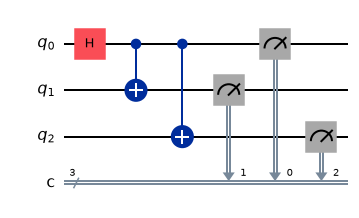

In [2]:
ghz = QuantumCircuit(3, 3)
ghz.h(0)
ghz.cx(0, 1)
ghz.cx(0, 2)
ghz.measure([0, 1, 2], [0, 1, 2])

print(ghz)            # same as print(ghz.draw("text"))
ghz.draw("mpl")       # the last expression of a cell is displayed: here a Matplotlib Figure

output='text'          -> TextDrawing
output='mpl'           -> Figure
output='latex_source'  -> str
circuit_drawer(ghz, output='mpl') -> Figure
\documentclass[border=2px]{standalone}

\usepackage[braket, qm]{qcircuit}
\usepackage{graphicx}

\begin{document}
\scalebox{1.0}{
\Qcircuit @C=1.0em @ ...


<class 'PIL.Image.Image'>


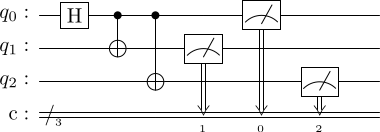

In [3]:
for out in ["text", "mpl", "latex_source"]:
    print(f"output={out!r:15} -> {type(ghz.draw(output=out)).__name__}")
print("circuit_drawer(ghz, output='mpl') ->", type(circuit_drawer(ghz, output="mpl")).__name__)
print(ghz.draw("latex_source")[:150], "...")

# The LaTeX drawer calls pdflatex; guard it so the notebook also runs without a TeX installation.
try:
    img = ghz.draw("latex")
    print(type(img))
    display(img)
except Exception as err:          # MissingOptionalLibraryError if pdflatex / poppler are missing
    print("LaTeX drawer not available here:", type(err).__name__)

Learn the four return types as a set: `"text"` gives a `TextDrawing`, `"mpl"` a Matplotlib `Figure`, `"latex"` a `PIL` image and `"latex_source"` a plain `str`. `circuit_drawer(qc, output="mpl")` is interchangeable with `qc.draw("mpl")`.

### 2.1.2 Reading a circuit diagram

These conventions hold for every drawer:

- Wires are listed from qubit 0 at the top. `q_0` is the top wire unless `reverse_bits=True`.
- Each classical register is bundled into one double line labelled like `c: 3/`. The small number where a measurement meets that line is the classical bit that receives the result. `cregbundle=False` draws one wire per bit.
- Controls are dots (`■` in text). A CNOT target is `⊕` in mpl and an `X` box in text. A barrier is `░` in text and a grey band in mpl. A measurement is an `M` box (a meter symbol in mpl) with a double line down to the classical wire.
- A `global phase: ...` line above the wires appears when the circuit has a non-zero global phase, which is common after transpilation.
- Bitstrings are read the other way round. In a counts key, classical bit 0 is the rightmost character (little-endian). In the GHZ diagram above, `q_1` is measured into `c_1`, which is the middle character of `'c2 c1 c0'`.

The diagram lists wires top-down from `q_0`, while a bitstring lists bits from `c_{n-1}` on the left to `c_0` on the right. `reverse_bits=True` only flips the drawing so that it matches the bitstring order (highest index on top). It does not change the circuit, the state or the counts.

### 2.1.3 Drawing options

| Option | Default | Effect | Drawers |
|---|---|---|---|
| `reverse_bits` | `False` | highest-index qubit (and clbit) on top | all |
| `plot_barriers` | `True` | `False` hides barriers; they stay in the circuit | all |
| `initial_state` | `False` | labels the start of every qubit wire with ket zero and every classical wire with `0` | all |
| `idle_wires` | `"auto"` | `False` drops wires with no operations; `"auto"` hides them only when the circuit has a layout (after transpilation) | all |
| `justify` | `"left"` | `"left"`, `"right"` or `"none"` (one gate per column) | all |
| `cregbundle` | `True` | `False` draws one wire per classical bit (Qiskit also switches it off by itself when an instruction needs single bits) | all |
| `fold` | text: 80 characters in Jupyter; mpl: 25 layers | where the drawing wraps; `fold=-1` switches wrapping off | text, mpl |
| `style` | `"iqp"` | `"iqp"`, `"iqp-dark"`, `"clifford"`, `"textbook"`, `"bw"`, a JSON file or a dict | mpl, latex |
| `scale` | `1.0` | image size factor | mpl, latex |
| `ax` | `None` | draw into an existing Matplotlib `Axes`; then `draw()` returns `None` | mpl |
| `wire_order` | `None` | explicit list of wire positions (not allowed together with `reverse_bits=True`) | all |
| `with_layout` | `True` | show `virtual -> physical` labels on transpiled circuits | all |
| `vertical_compression` | `"medium"` | `"high"`, `"medium"`, `"low"` line spacing | text |

In [4]:
demo = QuantumCircuit(3, 3)
demo.h(0)
demo.cx(0, 1)
demo.barrier()
demo.x(2)
demo.cx(1, 2)
demo.measure([0, 1, 2], [0, 1, 2])

print(demo.draw(reverse_bits=True))       # q_2 on top: the same order as a bitstring 'c2 c1 c0'

# initial_state labels the wires, plot_barriers=False hides the barrier (it is still in the circuit)
print(demo.draw(initial_state=True, plot_barriers=False))
print("barrier still in the circuit:", "barrier" in demo.count_ops())

                ░ ┌───┐┌───┐   ┌─┐
q_2: ───────────░─┤ X ├┤ X ├───┤M├
          ┌───┐ ░ └───┘└─┬─┘┌─┐└╥┘
q_1: ─────┤ X ├─░────────■──┤M├─╫─
     ┌───┐└─┬─┘ ░  ┌─┐      └╥┘ ║ 
q_0: ┤ H ├──■───░──┤M├───────╫──╫─
     └───┘      ░  └╥┘       ║  ║ 
c: 3/═══════════════╩════════╩══╩═
                    0        1  2 
        ┌───┐           ┌─┐           
q_0: |0>┤ H ├──■────────┤M├───────────
        └───┘┌─┴─┐      └╥┘     ┌─┐   
q_1: |0>─────┤ X ├───────╫───■──┤M├───
             └───┘ ┌───┐ ║ ┌─┴─┐└╥┘┌─┐
q_2: |0>───────────┤ X ├─╫─┤ X ├─╫─┤M├
                   └───┘ ║ └───┘ ║ └╥┘
 c: 0 3/═════════════════╩═══════╩══╩═
                         0       1  2 
barrier still in the circuit: True


In [5]:
small = QuantumCircuit(3)
small.h(0)
small.x(2)
small.cx(0, 1)

for j in ["left", "right", "none"]:        # where may a gate sit if several columns are possible?
    print(f'justify="{j}"')
    print(small.draw(justify=j))

justify="left"
     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
     ┌───┐└───┘
q_2: ┤ X ├─────
     └───┘     
justify="right"
     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          ├───┤
q_2: ─────┤ X ├
          └───┘
justify="none"
     ┌───┐          
q_0: ┤ H ├──■───────
     └───┘┌─┴─┐     
q_1: ─────┤ X ├─────
          └───┘┌───┐
q_2: ──────────┤ X ├
               └───┘


In [6]:
wide = QuantumCircuit(5)
wide.h(0)
wide.cx(0, 3)
print(wide.draw(idle_wires=False))         # q_1, q_2 and q_4 are dropped from the picture

long_qc = QuantumCircuit(2)
for _ in range(6):
    long_qc.h(0)
    long_qc.cx(0, 1)
print(long_qc.draw(fold=40))               # wraps after 40 characters; the » marks continue the line

     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_3: ─────┤ X ├
          └───┘
     ┌───┐     ┌───┐     ┌───┐     »
q_0: ┤ H ├──■──┤ H ├──■──┤ H ├──■──»
     └───┘┌─┴─┐└───┘┌─┴─┐└───┘┌─┴─┐»
q_1: ─────┤ X ├─────┤ X ├─────┤ X ├»
          └───┘     └───┘     └───┘»
«     ┌───┐     ┌───┐     ┌───┐     
«q_0: ┤ H ├──■──┤ H ├──■──┤ H ├──■──
«     └───┘┌─┴─┐└───┘┌─┴─┐└───┘┌─┴─┐
«q_1: ─────┤ X ├─────┤ X ├─────┤ X ├
«          └───┘     └───┘     └───┘


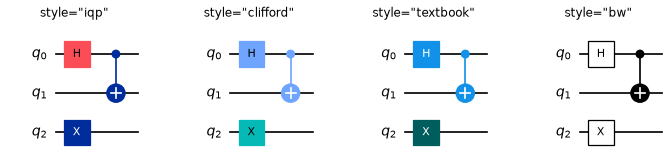

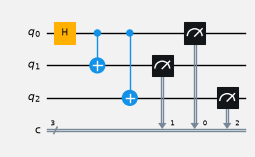

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(12, 2.4))
for ax, name in zip(axes, ["iqp", "clifford", "textbook", "bw"]):
    small.draw("mpl", style=name, ax=ax)   # with ax=... the method draws into ax and returns None
    ax.set_title(f'style="{name}"')
plt.show()

my_style = {
    "name": "textbook",                                # start from a built-in style ...
    "backgroundcolor": "#F2F2F2",                      # ... and override single entries
    "displaycolor": {"h": ["#FFB000", "#000000"]},     # gate name -> [box colour, text colour]
}
ghz.draw("mpl", style=my_style, scale=0.7)

> **Deeper API practice — optional on the first pass.** Unknown style-key behaviour is a drawer implementation detail.

Keys in a `style` dictionary that Qiskit does not know (for example a misspelt `"fontColor"`) are silently ignored: no `TypeError`, no warning, the default is used. An unknown style name such as `style="neon"` gives a `UserWarning` and falls back to `"iqp"`. By contrast, an invalid `output=` value raises `VisualizationError`.

### 2.1.4 Composite gates: look inside with `decompose()`

A sub-circuit turned into a gate (`to_gate()` or `to_instruction()`) or a library gate such as `QFTGate` is drawn as one labelled box across its qubits. The numbers on the left edge of the box are the gate's own qubit indices (0, 1, ...), not circuit indices. To see the contents:

- `qc.decompose()` expands every instruction that has a definition by one level. That includes standard gates such as `ccx` and `swap`.
- `qc.decompose("bell")` expands only matching instructions. You can pass a name, a label, a gate class, or a list of them; wildcards such as `"q*"` work too.
- `qc.decompose(reps=2)` equals `qc.decompose().decompose()`.
- `decompose()` returns a new circuit and leaves `qc` unchanged.

In [8]:
bell_gate = QuantumCircuit(2, name="bell")
bell_gate.h(0)
bell_gate.cx(0, 1)

comp = QuantumCircuit(3)
comp.append(bell_gate.to_gate(), [0, 1])
comp.append(QFTGate(3), [0, 1, 2])
comp.ccx(0, 1, 2)
print(comp.draw())
print("ops:", dict(comp.count_ops()))

only_bell = comp.decompose("bell")            # open just the 'bell' box
print(only_bell.draw())
print("ops:", dict(only_bell.count_ops()))

     ┌───────┐┌──────┐     
q_0: ┤0      ├┤0     ├──■──
     │  bell ││      │  │  
q_1: ┤1      ├┤1 Qft ├──■──
     └───────┘│      │┌─┴─┐
q_2: ─────────┤2     ├┤ X ├
              └──────┘└───┘
ops: {'bell': 1, 'qft': 1, 'ccx': 1}
     ┌───┐     ┌──────┐     
q_0: ┤ H ├──■──┤0     ├──■──
     └───┘┌─┴─┐│      │  │  
q_1: ─────┤ X ├┤1 Qft ├──■──
          └───┘│      │┌─┴─┐
q_2: ──────────┤2     ├┤ X ├
               └──────┘└───┘
ops: {'h': 1, 'cx': 1, 'qft': 1, 'ccx': 1}


decompose()       ops: {'cx': 7, 'h': 6, 't': 4, 'cp': 3, 'tdg': 3, 'swap': 1}
decompose(reps=2) ops: {'cx': 16, 'p': 9, 'u1': 7, 'u2': 6}


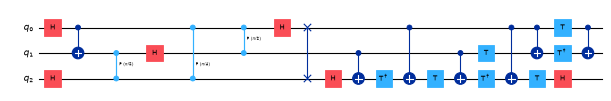

In [9]:
one_level = comp.decompose()                  # every box one level down, ccx included
print("decompose()       ops:", dict(one_level.count_ops()))
print("decompose(reps=2) ops:", dict(comp.decompose(reps=2).count_ops()))
one_level.draw("mpl", fold=-1, scale=0.55)

`decompose()` is not "open my custom gates only". It expands every gate that has a definition by one level, so a `ccx` becomes six `cx` plus `h`, `t` and `tdg` gates, and a `swap` becomes three `cx`. It is also not transpilation: the result is not mapped to any backend basis or coupling map.

Prefer the circuit-library functions (`real_amplitudes`, `efficient_su2`, `zz_feature_map`, `n_local`, ...). In Qiskit 2.0 the class forms (`RealAmplitudes`, `EfficientSU2`, `ZZFeatureMap`, `NLocal`) are pending deprecation. The functions return ordinary circuits, so `draw()` shows their gates directly, while a class object is drawn as one large box until you call `decompose()`.

### Practice 2.1 — Text drawing with options

`ex1_qc` has a barrier and three measurements. Store in `ex1_text` a string holding its text drawing in which

1. `q_2` is the top wire,
2. the barrier is not drawn (but stays in the circuit), and
3. every qubit wire starts with `|0>`.

Hint: `str()` turns a `TextDrawing` into a string.

In [ ]:
ex1_qc = QuantumCircuit(3, 3)
ex1_qc.h(0)
ex1_qc.cx(0, 1)
ex1_qc.barrier()
ex1_qc.cx(1, 2)
ex1_qc.measure([0, 1, 2], [0, 1, 2])

ex1_text = None  # TODO: str(ex1_qc.draw(...))
print(ex1_text)

In [ ]:
# Run this cell to check your answer
assert isinstance(ex1_text, str), "ex1_text must be a str: wrap the drawing in str(...)"
rows = {q: i for i, line in enumerate(ex1_text.splitlines())
        for q in ("q_0", "q_1", "q_2") if line.lstrip().startswith(q + ":")}
assert len(rows) == 3, "all three qubit wires should appear in the drawing"
assert rows["q_2"] < rows["q_1"] < rows["q_0"], "q_2 must be the top wire (reverse_bits=True)"
assert "░" not in ex1_text, "the barrier is still drawn (plot_barriers=False)"
assert "|0>" in ex1_text, "initial_state=True starts each qubit wire with |0>"
assert "barrier" in ex1_qc.count_ops(), "hide the barrier in the drawing, do not remove it from the circuit"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex1_qc = QuantumCircuit(3, 3)
ex1_qc.h(0)
ex1_qc.cx(0, 1)
ex1_qc.barrier()
ex1_qc.cx(1, 2)
ex1_qc.measure([0, 1, 2], [0, 1, 2])

ex1_text = str(ex1_qc.draw(output="text", reverse_bits=True, plot_barriers=False, initial_state=True))
print(ex1_text)
```

All three are drawing options, so the circuit is untouched. `reverse_bits=True` puts `q_2` on top, `plot_barriers=False` hides the `░` column and `initial_state=True` writes `|0>` (and `0` on the classical wire) at the start. Deleting the barrier from the circuit would also remove it from the picture, but it changes the circuit, which the check rejects.

</details>

### Practice 2.2 — Open one box, then all boxes

`ex2_qc` contains a custom gate named `prep` and a Toffoli (`ccx`). Create

- `ex2_prep_only`: a copy where only `prep` is expanded (the `ccx` must stay a `ccx`), and
- `ex2_one_level`: a copy where every instruction is expanded by one level.

Print both drawings and compare them.

In [ ]:
ex2_prep = QuantumCircuit(2, name="prep")
ex2_prep.h(0)
ex2_prep.cx(0, 1)

ex2_qc = QuantumCircuit(3)
ex2_qc.append(ex2_prep.to_gate(), [0, 1])
ex2_qc.ccx(0, 1, 2)
print(ex2_qc.draw())

ex2_prep_only = None   # TODO
ex2_one_level = None   # TODO

In [ ]:
# Run this cell to check your answer
assert isinstance(ex2_prep_only, QuantumCircuit) and isinstance(ex2_one_level, QuantumCircuit),     "set both ex2_prep_only and ex2_one_level to circuits returned by decompose(...)"
ops_a, ops_b = ex2_prep_only.count_ops(), ex2_one_level.count_ops()
assert "prep" not in ops_a, "ex2_prep_only: the prep box should be opened"
assert ops_a.get("ccx") == 1, "ex2_prep_only: the ccx must not be expanded (use the name filter)"
assert "prep" not in ops_b and "ccx" not in ops_b, "ex2_one_level: decompose() expands every gate one level"
assert ex2_qc.count_ops().get("prep") == 1, "decompose() returns a new circuit; ex2_qc must be unchanged"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex2_prep = QuantumCircuit(2, name="prep")
ex2_prep.h(0)
ex2_prep.cx(0, 1)

ex2_qc = QuantumCircuit(3)
ex2_qc.append(ex2_prep.to_gate(), [0, 1])
ex2_qc.ccx(0, 1, 2)
print(ex2_qc.draw())

ex2_prep_only = ex2_qc.decompose("prep")
ex2_one_level = ex2_qc.decompose()
print(ex2_prep_only.draw())
print(ex2_one_level.draw(fold=-1))
```

`decompose("prep")` matches by name, so only that box opens. `decompose()` without arguments expands every instruction that has a definition, including the Toffoli, which becomes `h`, `t`, `tdg` and six `cx`. Both calls return new circuits.

</details>

Q2.1. Which call returns a Python `str`?

A. `qc.draw()`

B. `qc.draw("latex_source")`

C. `qc.draw("latex")`

D. `print(qc)`

<details>
<summary>Show answer</summary>

Answer: B

`"latex_source"` returns the qcircuit LaTeX code as a string. `qc.draw()` returns a `TextDrawing` object (it prints as ASCII art but is not a `str`), `"latex"` returns a `PIL` image, and `print(qc)` returns `None` after printing the text drawing.

</details>

### 2.1.5 Reading dynamic circuits (`if_test`, `if_else`, `switch`, loops)

Qiskit 2.x writes classical feed-forward with control-flow blocks (`c_if` was removed in Qiskit 2.0). The text and mpl drawers show each block as a bracket over the wires it acts on:

| In the drawing | Code |
|---|---|
| `If-0` ... `End-0` | `with qc.if_test(condition):` |
| `If-0` ... `Else-0` ... `End-0` | `with qc.if_test(condition) as else_:` then `with else_:` (or `qc.if_else(...)`) |
| `Switch-0`, `Case-0 (1, 2)`, `Case-0 default` | `with qc.switch(target) as case:` and `with case(1, 2):` |
| `For-0 range(0, 3)`, `While-0` | `for_loop`, `while_loop` |
| the number after the dash | nesting depth: an `if` inside an `if` is drawn `If-1` |

The condition sits on the classical wire. A single-bit condition `(clbit, 1)` shows as `c_0=0x1`. A register condition `(creg, 3)` shows the value in hex, `0x3`. A `qiskit.circuit.classical.expr` condition shows `[expr]`, with the expression text in the block label.

     ┌───┐┌─┐                                            
q_0: ┤ H ├┤M├────────────────────────────────────────────
     └───┘└╥┘  ┌──────  ┌───┐┌──────── ┌───┐ ───────┐ ┌─┐
q_1: ──────╫───┤ If-0  ─┤ X ├┤ Else-0  ┤ H ├  End-0 ├─┤M├
           ║   └──╥───  └───┘└──────── └───┘ ───────┘ └╥┘
           ║ ┌────╨────┐                               ║ 
c: 2/══════╩═╡ c_0=0x1 ╞═══════════════════════════════╩═
           0 └─────────┘                               1 


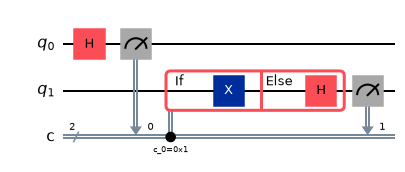

In [10]:
qr = QuantumRegister(2, "q")
cr = ClassicalRegister(2, "c")
dyn = QuantumCircuit(qr, cr)
dyn.h(0)
dyn.measure(0, 0)
with dyn.if_test((cr[0], 1)) as else_:    # if c_0 == 1
    dyn.x(1)
with else_:                                # else
    dyn.h(1)
dyn.measure(1, 1)

print(dyn.draw())
dyn.draw("mpl")

In [11]:
nest = QuantumCircuit(3, 2)
nest.h(0)
nest.measure(0, 0)
with nest.if_test((nest.clbits[0], 1)):          # outer block: If-0
    nest.h(1)
    nest.measure(1, 1)
    with nest.if_test((nest.cregs[0], 3)):       # inner block on the whole register: If-1, value 0x3
        nest.x(2)
print(nest.draw())

     ┌───┐┌─┐                                                    
q_0: ┤ H ├┤M├────────────────────────────────────────────────────
     └───┘└╥┘  ┌──────  ┌───┐┌─┐                        ───────┐ 
q_1: ──────╫───┤       ─┤ H ├┤M├───────────────────────        ├─
           ║   │ If-0   └───┘└╥┘┌────── ┌───┐ ───────┐   End-0 │ 
q_2: ──────╫───┤       ───────╫─┤ If-1  ┤ X ├  End-1 ├─        ├─
           ║   └──╥───        ║ └──╥─── └───┘ ───────┘  ───────┘ 
           ║ ┌────╨────┐      ║ ┌──╨──┐                          
c: 2/══════╩═╡ c_0=0x1 ╞══════╩═╡ 0x3 ╞══════════════════════════
           0 └─────────┘      1 └─────┘                          


Older material draws a conditioned gate (`c_if`) as a normal gate box joined to the classical register by a line with `= 0x1`. That construction does not exist in Qiskit 2.x. A 2.x diagram of a conditional operation shows an `If-0 ... End-0` bracket, and the value on the classical wire is the value tested, written in hex.

### Practice 2.3 — Rebuild a dynamic circuit from its drawing

Build `ex3_qc` (3 qubits, 2 classical bits, default register names `q` and `c`) so that `print(ex3_qc.draw(fold=-1))` shows exactly this diagram:

```text
     ┌───┐┌─┐                                                                   
q_0: ┤ H ├┤M├───────────────────────────────────────────────────────────────────
     └───┘└╥┘  ┌──────  ┌───┐┌──────── ┌───┐ ───────┐ ┌─┐                       
q_1: ──────╫───┤ If-0  ─┤ X ├┤ Else-0  ┤ H ├  End-0 ├─┤M├───────────────────────
           ║   └──╥───  └───┘└──────── └───┘ ───────┘ └╥┘┌────── ┌───┐ ───────┐ 
q_2: ──────╫──────╫────────────────────────────────────╫─┤ If-0  ┤ X ├  End-0 ├─
           ║      ║                                    ║ └──╥─── └───┘ ───────┘ 
           ║ ┌────╨────┐                               ║ ┌──╨──┐                
c: 2/══════╩═╡ c_0=0x1 ╞═══════════════════════════════╩═╡ 0x3 ╞════════════════
           0 └─────────┘                               1 └─────┘                
```

Use `if_test` blocks (the `c_if` method no longer exists in Qiskit 2.x).

In [ ]:
ex3_qc = QuantumCircuit(3, 2)
# TODO: add the operations shown in the diagram

print(ex3_qc.draw(fold=-1))

In [ ]:
# Run this cell to check your answer
target = '     ┌───┐┌─┐                                                                   \nq_0: ┤ H ├┤M├───────────────────────────────────────────────────────────────────\n     └───┘└╥┘  ┌──────  ┌───┐┌──────── ┌───┐ ───────┐ ┌─┐                       \nq_1: ──────╫───┤ If-0  ─┤ X ├┤ Else-0  ┤ H ├  End-0 ├─┤M├───────────────────────\n           ║   └──╥───  └───┘└──────── └───┘ ───────┘ └╥┘┌────── ┌───┐ ───────┐ \nq_2: ──────╫──────╫────────────────────────────────────╫─┤ If-0  ┤ X ├  End-0 ├─\n           ║      ║                                    ║ └──╥─── └───┘ ───────┘ \n           ║ ┌────╨────┐                               ║ ┌──╨──┐                \nc: 2/══════╩═╡ c_0=0x1 ╞═══════════════════════════════╩═╡ 0x3 ╞════════════════\n           0 └─────────┘                               1 └─────┘                '
mine = str(ex3_qc.draw(fold=-1))
if mine != target:
    print('Your drawing:')
    print(mine)
assert mine == target, 'the drawing differs from the target: compare the blocks, conditions and wires'
print('Correct!')

<details>
<summary>Show solution</summary>

```python
ex3_qc = QuantumCircuit(3, 2)
ex3_qc.h(0)
ex3_qc.measure(0, 0)
with ex3_qc.if_test((ex3_qc.clbits[0], 1)) as else_:
    ex3_qc.x(1)
with else_:
    ex3_qc.h(1)
ex3_qc.measure(1, 1)
with ex3_qc.if_test((ex3_qc.cregs[0], 3)):
    ex3_qc.x(2)

print(ex3_qc.draw(fold=-1))
```

Read the blocks left to right. `If-0 ... Else-0 ... End-0` on `q_1` with `c_0=0x1` on the classical wire is an `if_test` on bit `c_0` equal to 1, with `x(1)` in the true branch and `h(1)` in the else branch. The second block tests the whole register: `0x3` means `c == 3`, that is binary `11`, both bits equal to 1. The body applies `x(2)`.

</details>

Q2.2. Which diagram does this code draw with `qc.draw("mpl")`?

```python
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.measure(0, 0)
with qc.if_test((qc.clbits[0], 1)):
    qc.x(1)
qc.measure(1, 1)
```

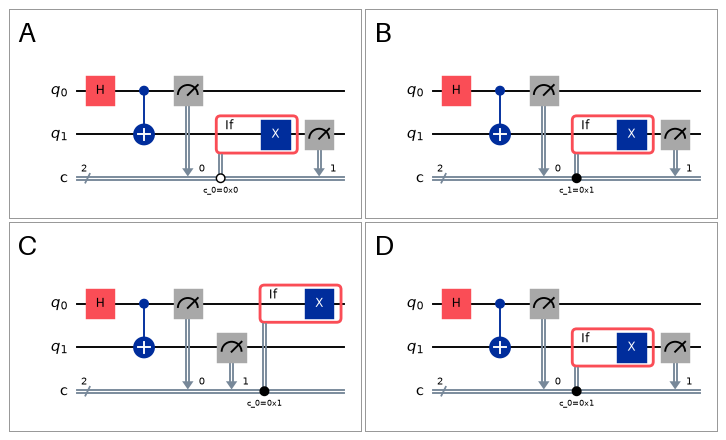

A. Diagram A

B. Diagram B

C. Diagram C

D. Diagram D

<details>
<summary>Show answer</summary>

Answer: D

The block must sit on `q_1` (the `x` acts on qubit 1) and the condition box on the classical wire must read `c_0=0x1` (bit `c_0` equal to 1). A tests the value 0 (`c_0=0x0`), B tests bit `c_1`, which has not been measured yet at that point, and C puts the `X` inside the block on `q_0`.

</details>

### 2.1.6 Transpiled circuits, layouts and backend plots

After transpilation a circuit acts on the physical qubits of a backend and carries a `layout`. The drawers then

- label each wire `virtual -> physical`, e.g. `q_0 -> 3` means virtual qubit 0 runs on physical qubit 3 (`with_layout=False` prints the physical names `q_3` instead);
- hide idle wires by default, because `idle_wires="auto"` shows idle wires only for circuits without a layout. Pass `idle_wires=True` to see the unused `ancilla_k -> p` wires;
- print the accumulated `global phase` above the wires.

In [12]:
backend = FakeManilaV2()                     # 5-qubit fake device: runs offline
pm = generate_preset_pass_manager(optimization_level=1, backend=backend, seed_transpiler=7)
ghz_isa = pm.run(ghz)

print(ghz_isa.draw())                        # physical qubits 0 and 1 are idle -> hidden
print("virtual -> physical:", ghz_isa.layout.final_index_layout())
print(ghz_isa.draw(idle_wires=True))         # now the ancilla wires appear as well

global phase: π/4
                                     ┌───┐     ┌─┐      
q_1 -> 2 ────────────────────────────┤ X ├─────┤M├──────
         ┌─────────┐┌────┐┌─────────┐└─┬─┘     └╥┘┌─┐   
q_0 -> 3 ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├──■────■───╫─┤M├───
         └─────────┘└────┘└─────────┘     ┌─┴─┐ ║ └╥┘┌─┐
q_2 -> 4 ─────────────────────────────────┤ X ├─╫──╫─┤M├
                                          └───┘ ║  ║ └╥┘
    c: 3/═══════════════════════════════════════╩══╩══╩═
                                                1  0  2 
virtual -> physical: [3, 2, 4]
global phase: π/4
                                                              
ancilla_0 -> 0 ───────────────────────────────────────────────
                                                              
ancilla_1 -> 1 ───────────────────────────────────────────────
                                           ┌───┐     ┌─┐      
      q_1 -> 2 ────────────────────────────┤ X ├─────┤M├──────
               ┌─────────┐┌────┐┌─────────

Qiskit also plots the device itself. All four functions below draw the qubit graph with Graphviz, so they raise `MissingOptionalLibraryError` unless the Graphviz system package (`dot`) is installed (`brew install graphviz`, `sudo apt install graphviz`, or `conda install graphviz`); the pip package `graphviz` alone is not enough. `plot_error_map` also needs seaborn, which comes with `qiskit[visualization]`.

| Function | Shows |
|---|---|
| `plot_gate_map(backend)` | qubits and couplers of the device |
| `plot_coupling_map(num_qubits, qubit_coordinates, coupling_map)` | the same kind of picture from plain lists, no backend needed |
| `plot_circuit_layout(isa_circuit, backend, view="virtual")` | which physical qubits a transpiled circuit uses (dark) and their virtual indices; `view="physical"` labels physical indices |
| `plot_error_map(backend)` | colour-coded single-qubit and two-qubit error rates plus readout-error bar charts |

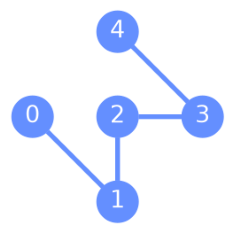

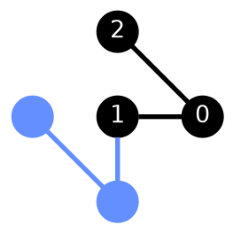

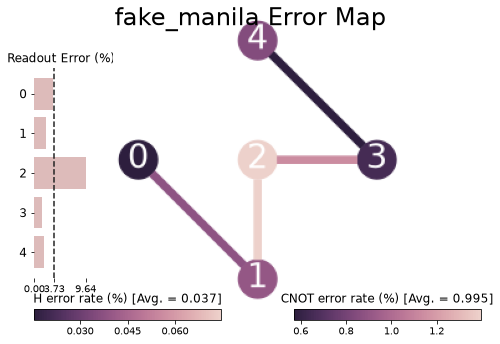

In [13]:
if HAS_GRAPHVIZ:
    display(plot_gate_map(backend))
    display(plot_circuit_layout(ghz_isa, backend))
    display(plot_error_map(backend, figsize=(8, 5.5)))
else:
    print("Graphviz (dot) is not installed, so the device plots are skipped.")
    print(f"{backend.name}: {backend.num_qubits} qubits, couplers {sorted(backend.coupling_map.get_edges())}")

Q2.3. A 3-qubit GHZ circuit was transpiled for a 5-qubit device, and `print(isa.draw())` shows:

```text
global phase: π/4
                                     ┌───┐     ┌─┐      
q_1 -> 2 ────────────────────────────┤ X ├─────┤M├──────
         ┌─────────┐┌────┐┌─────────┐└─┬─┘     └╥┘┌─┐   
q_0 -> 3 ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├──■────■───╫─┤M├───
         └─────────┘└────┘└─────────┘     ┌─┴─┐ ║ └╥┘┌─┐
q_2 -> 4 ─────────────────────────────────┤ X ├─╫──╫─┤M├
                                          └───┘ ║  ║ └╥┘
    c: 3/═══════════════════════════════════════╩══╩══╩═
                                                1  0  2 
```

Which statement is correct?

A. Virtual qubit `q_1` runs on physical qubit 2, and the unused physical qubits 0 and 1 are not drawn because `idle_wires` defaults to `"auto"`.

B. The circuit runs on physical qubits 0, 1 and 2; the numbers after the arrows are only display positions.

C. `q_0 -> 3` means that qubit 3 of the original circuit was placed on physical qubit 0.

D. The `global phase` line is an extra gate that the transpiler inserted and that will be executed on the device.

<details>
<summary>Show answer</summary>

Answer: A

Layout labels read `virtual -> physical`, so `q_1 -> 2` puts virtual qubit 1 on physical qubit 2 (C reverses the direction, B ignores the arrows). Transpiled circuits carry a layout, and `idle_wires="auto"` then hides wires with no operations; `idle_wires=True` would show `ancilla_0 -> 0` and `ancilla_1 -> 1`. The global phase is a property of the circuit, not an instruction, and has no observable effect (D).

</details>

<a id="s2-core-42"></a>

## 2.2 Visualize quantum measurements

### 2.2.1 From a sampler result to a counts dictionary

The histogram functions take a dictionary `{bitstring: value}`. With the V2 primitives you get it from the result of a PUB. The attribute after `.data` is the name of the classical register. `QuantumCircuit(n, n)` names it `c`, `measure_all()` creates a register called `meas`, and `ClassicalRegister(n, "alpha")` gives `alpha`. Here the Runtime `SamplerV2` runs locally on `AerSimulator` (Qiskit also ships exact reference primitives, but the Runtime pattern is the one the exam tests); Section 5 covers the sampler itself.

In [14]:
aer = AerSimulator()                                   # ideal local simulator; h, cx, measure are native gates
sampler = SamplerV2(mode=aer)
sampler.options.simulator.seed_simulator = 11          # reproducible shots
ghz_counts = sampler.run([ghz], shots=1000).result()[0].data.c.get_counts()
print(ghz_counts)

{'111': 494, '000': 506}


### 2.2.2 `plot_histogram` and `plot_distribution`

| | `plot_histogram(data)` | `plot_distribution(data)` |
|---|---|---|
| intended input | counts (integers) | counts, probabilities or quasi-probabilities |
| y axis | raw counts, label `Count`; if the values are floats it normalises them like `plot_distribution` | always normalised to sum 1, label `Quasi-probability` |
| bar labels (`bar_labels=True`) | integer counts | probabilities rounded to 3 decimals |
| default `figsize` | Matplotlib default (6.4 x 4.8 in) | (7, 5) in |

Both return a Matplotlib `Figure` (or draw into `ax=` and return `None`), accept one dictionary or a list of dictionaries, and share the options below.

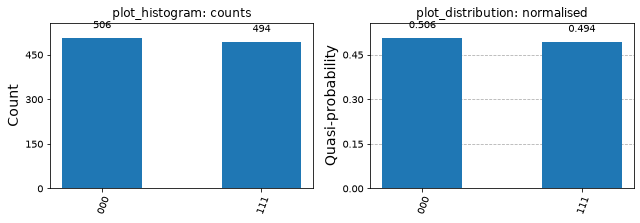

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
plot_histogram(ghz_counts, ax=axes[0])               # with ax=... nothing is returned
plot_distribution(ghz_counts, ax=axes[1])
axes[0].set_title("plot_histogram: counts")
axes[1].set_title("plot_distribution: normalised")
plt.tight_layout()
plt.show()

### 2.2.3 Options that change the picture

| Option | Default | What it does |
|---|---|---|
| `legend` | `None` | one label per dictionary in the list; a length mismatch raises `VisualizationError` |
| `color` | Matplotlib colour cycle | one colour, or a list with one colour per dataset |
| `sort` | `"asc"` | `"asc"` / `"desc"` by bitstring, `"value"` / `"value_desc"` by bar height, `"hamming"` by Hamming distance from `target_string` |
| `target_string` | `None` | reference bitstring; required with `sort="hamming"` (otherwise `VisualizationError`) |
| `number_to_keep` | `None` | keep the N largest outcomes of each dataset and add their remainder as one bar called `rest` |
| `bar_labels` | `True` | print the value above each bar |
| `title`, `figsize`, `ax`, `filename` | | title, size in inches, target Axes, save to file |

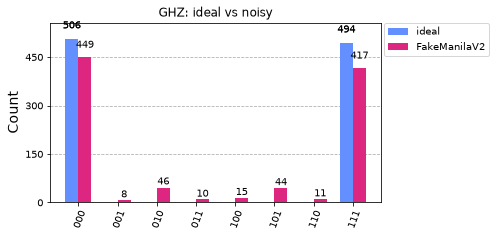

In [16]:
# A noisy run: AerSimulator built from the FakeManilaV2 device model (coupling map, basis gates, noise);
# ghz_isa was transpiled for that device in 2.1.6
noisy_sampler = SamplerV2(mode=AerSimulator.from_backend(backend))
noisy_sampler.options.simulator.seed_simulator = 42
noisy_counts = noisy_sampler.run([ghz_isa], shots=1000).result()[0].data.c.get_counts()

plot_histogram([ghz_counts, noisy_counts], legend=["ideal", "FakeManilaV2"],
               color=["#648fff", "#dc267f"], title="GHZ: ideal vs noisy", figsize=(7, 3.4))

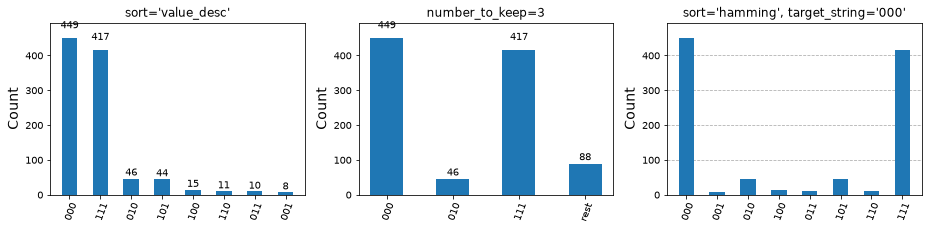

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
plot_histogram(noisy_counts, ax=axes[0], sort="value_desc")
plot_histogram(noisy_counts, ax=axes[1], number_to_keep=3)
plot_histogram(noisy_counts, ax=axes[2], sort="hamming", target_string="000", bar_labels=False)
for ax, t in zip(axes, ["sort='value_desc'", "number_to_keep=3", "sort='hamming', target_string='000'"]):
    ax.set_title(t)
plt.tight_layout()
plt.show()

Use a list of dictionaries plus `legend=[...]` to compare runs (ideal vs noisy, two backends, before and after mitigation). The legend needs exactly one entry per dictionary. With `number_to_keep=N` you get at most N bars plus one `rest` bar per dataset.

### 2.2.4 Reading bitstrings on the x axis (little-endian)

A key such as `'001'` lists the classical bits as `c2 c1 c0`, so `c_0` is the rightmost character. The key follows the classical bits, so the `measure(qubit, clbit)` mapping decides where a qubit's result ends up.

In [18]:
le = QuantumCircuit(3, 3)
le.x(0)                                   # only qubit 0 is flipped
le.measure([0, 1, 2], [0, 1, 2])
print(sampler.run([le], shots=100).result()[0].data.c.get_counts())           # {'001': 100}

le_swapped = QuantumCircuit(3, 3)
le_swapped.x(0)
le_swapped.measure([0, 1, 2], [2, 1, 0])  # qubit 0 -> clbit 2 (leftmost character)
print(sampler.run([le_swapped], shots=100).result()[0].data.c.get_counts())   # {'100': 100}

{'001': 100}
{'100': 100}


Reading a histogram label left to right as `q0 q1 q2` is the most common mistake in this section. Write the classical-bit indices under the key from right to left (`2 1 0`), then map each clbit back to its qubit through the `measure` calls.

### Practice 2.4 — Compare two runs in one histogram

Plot `ex4_run_a` and `ex4_run_b` side by side in one figure and store the returned figure in `ex4_fig`. The figure must have

- the legend entries `"run A"` and `"run B"` (in this order),
- the title `"Two runs"`,
- no numbers printed above the bars, and
- `figsize=(6, 3)`.

In [ ]:
ex4_run_a = {"00": 480, "01": 20, "10": 25, "11": 475}
ex4_run_b = {"00": 430, "01": 70, "10": 60, "11": 440}

ex4_fig = None  # TODO: plot_histogram(...)
ex4_fig

In [ ]:
# Run this cell to check your answer
import matplotlib.figure
assert isinstance(ex4_fig, matplotlib.figure.Figure), "store the Figure returned by plot_histogram in ex4_fig"
ax = ex4_fig.axes[0]
assert ax.get_legend() is not None, "pass legend=[...]"
assert [t.get_text() for t in ax.get_legend().get_texts()] == ["run A", "run B"], "legend entries/order"
assert ax.get_title() == "Two runs", "title"
assert len(ax.texts) == 0, "bar_labels=False removes the numbers above the bars"
assert tuple(np.round(ex4_fig.get_size_inches(), 2)) == (6.0, 3.0), "figsize=(6, 3)"
assert len(ax.patches) == 8, "both dictionaries (4 bars each) should be plotted"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex4_run_a = {"00": 480, "01": 20, "10": 25, "11": 475}
ex4_run_b = {"00": 430, "01": 70, "10": 60, "11": 440}

ex4_fig = plot_histogram([ex4_run_a, ex4_run_b], legend=["run A", "run B"],
                         title="Two runs", bar_labels=False, figsize=(6, 3))
ex4_fig
```

Passing a list plots the datasets as neighbouring bars in the order given, and `legend` labels them in the same order. `bar_labels=False` suppresses the value text, and `title` and `figsize` are ordinary keyword arguments. The function returns the `Figure`, which you can keep, save with `savefig`, or inspect as the check does.

</details>

### Practice 2.5 — From a histogram back to a circuit

A 2-qubit circuit that ends with `measure_all()` produced the histogram below (1000 shots): only `10` and `11`, about half each. Build `ex5_qc` with 2 qubits, ending with `measure_all()`, that reproduces this distribution.

Target histogram:

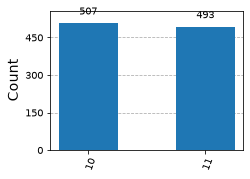

In [ ]:
ex5_qc = QuantumCircuit(2)
# TODO: add gates
ex5_qc.measure_all()

In [ ]:
# Run this cell to check your answer
assert ex5_qc.num_qubits == 2 and ex5_qc.num_clbits == 2, "use 2 qubits and measure_all()"
ex5_aer = AerSimulator()
ex5_isa = generate_preset_pass_manager(optimization_level=1, backend=ex5_aer).run(ex5_qc)
ex5_sampler = SamplerV2(mode=ex5_aer)
ex5_sampler.options.simulator.seed_simulator = 5
ex5_counts = ex5_sampler.run([ex5_isa], shots=2000).result()[0].data.meas.get_counts()
assert set(ex5_counts) == {"10", "11"}, f"got outcomes {sorted(ex5_counts)}; remember c_0 is the right character"
assert 0.4 < ex5_counts["10"] / 2000 < 0.6, "the two outcomes should be about equally likely"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex5_qc = QuantumCircuit(2)
ex5_qc.x(1)       # qubit 1 -> c_1 (left character) is always 1
ex5_qc.h(0)       # qubit 0 -> c_0 (right character) is 0 or 1 with equal probability
ex5_qc.measure_all()
```

In `'10'` and `'11'` the left character (`c_1`, from qubit 1) is always 1 and the right character (`c_0`, from qubit 0) varies. So qubit 1 gets an `x` and qubit 0 an `h`. Writing `x(0); h(1)` would give `'01'` and `'11'`, which is the endianness trap.

</details>

Q2.4. Which histogram can this code produce?

```python
qc = QuantumCircuit(3, 3)
qc.x(0)
qc.h(2)
qc.measure([0, 1, 2], [0, 1, 2])
sampler = SamplerV2(mode=AerSimulator())
counts = sampler.run([qc], shots=1000).result()[0].data.c.get_counts()
plot_histogram(counts)
```

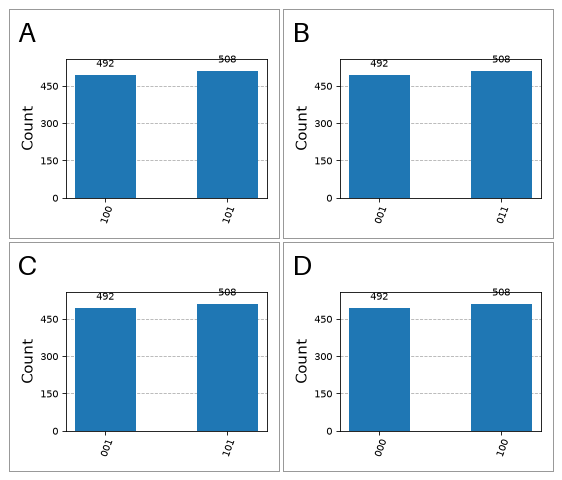

A. Histogram A

B. Histogram B

C. Histogram C

D. Histogram D

<details>
<summary>Show answer</summary>

Answer: C

Qubit 0 is always 1, qubit 1 always 0, qubit 2 random. In the key `c2 c1 c0` that gives `?01`, so `001` and `101`. A is what you get if you read the key left to right as `q0 q1 q2`. B would need the `h` on qubit 1, and D ignores the `x`.

</details>

Q2.5. What does `plot_distribution({"0": 300, "1": 100})` show?

A. Two bars of height 300 and 100, y axis labelled `Count`

B. Two bars of height 0.5 and 0.5, because each outcome is one distribution entry

C. Two bars of height 3 and 1, the ratio of the counts

D. Two bars of height 0.75 and 0.25, y axis labelled `Quasi-probability`

<details>
<summary>Show answer</summary>

Answer: D

`plot_distribution` always normalises the values to sum 1 (300/400 and 100/400) and labels the axis `Quasi-probability`. A describes `plot_histogram` with the same integer counts.

</details>

Q2.6. How many bars does this call draw?

```python
counts = {"000": 410, "011": 260, "101": 180, "110": 90, "111": 60}
plot_histogram(counts, number_to_keep=2)
```

A. 2

B. 3

C. 5

D. 6

<details>
<summary>Show answer</summary>

Answer: B

`number_to_keep=2` keeps the two largest outcomes (`000` and `011`) and sums the other three into a single `rest` bar (330), so there are 3 bars. It does not drop the remainder silently (A), and it does not add `rest` on top of all the original bars (D).

</details>

### 2.2.5 Plotting Estimator results

An Estimator returns expectation values, not counts, so the histogram functions do not apply, and Qiskit has no built-in plot for them. Plot `pub_result.data.evs` with Matplotlib and use `pub_result.data.stds`, the estimated standard error of each value, as error bars. The estimate is shot-based: with `EstimatorV2(mode=AerSimulator())` and a precision of 0.05 each point uses $\lceil 1/0.05^2 \rceil = 400$ shots, and an error bar is $\sqrt{1-\langle P\rangle^2}/\sqrt{400}$ for a Pauli $P$, so it shrinks where the value approaches $\pm 1$. Section 6 covers the Estimator itself.

evs shape: (2, 13) | shots: 400
stds of <Z>: [0.    0.025 0.046 0.05 ]


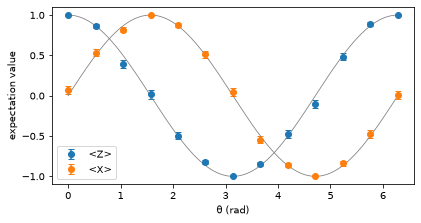

In [19]:
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp

theta = Parameter("θ")
ry_qc = QuantumCircuit(1)
ry_qc.ry(theta, 0)
thetas = np.linspace(0, 2 * np.pi, 13)
observables = [[SparsePauliOp("Z")], [SparsePauliOp("X")]]          # shape (2, 1)

estimator = EstimatorV2(mode=AerSimulator())
estimator.options.default_precision = 0.05           # about 1/0.05**2 = 400 shots per point
estimator.options.simulator.seed_simulator = 42
est_res = estimator.run([(ry_qc, observables, thetas.reshape(-1, 1))]).result()[0]
print("evs shape:", est_res.data.evs.shape, "| shots:", est_res.metadata["shots"])   # (2, 1) x (13,) -> (2, 13)
print("stds of <Z>:", np.round(est_res.data.stds[0, :4], 3))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
fine = np.linspace(0, 2 * np.pi, 200)
for row, (label, exact) in enumerate([("<Z>", np.cos(fine)), ("<X>", np.sin(fine))]):
    ax.errorbar(thetas, est_res.data.evs[row], yerr=est_res.data.stds[row], fmt="o", capsize=3, label=label)
    ax.plot(fine, exact, lw=0.8, color="grey")
ax.set_xlabel("θ (rad)")
ax.set_ylabel("expectation value")
ax.legend()
plt.show()

For Estimator output, think "values with error bars": `ax.errorbar(x, pub_result.data.evs, yerr=pub_result.data.stds)`. The shape of `evs` follows the broadcast of observables and parameter values, so index the rows you want to plot. Halving the error bars of a shot-based estimate needs four times as many shots.

Q2.7. A one-qubit circuit `qc.ry(θ, 0)` was run through an Estimator for 13 values of θ, and the result was plotted with `ax.errorbar(thetas, res.data.evs, yerr=res.data.stds)`. Which observable was measured?

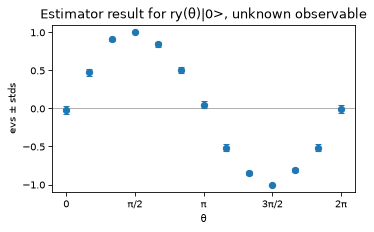

A. `SparsePauliOp("X")`

B. `SparsePauliOp("Z")`

C. `SparsePauliOp("Y")`

D. `SparsePauliOp("Z", coeffs=[-1])`

<details>
<summary>Show answer</summary>

Answer: A

$R_Y(\theta)|0\rangle = \cos\frac{\theta}{2}|0\rangle + \sin\frac{\theta}{2}|1\rangle$ has Bloch vector $(\sin\theta, 0, \cos\theta)$. The points start at 0, reach $+1$ at $\pi/2$ and $-1$ at $3\pi/2$, which is $\sin\theta = \langle X\rangle$. $\langle Z\rangle = \cos\theta$ would start at $+1$ (B) and $-Z$ at $-1$ (D), and $\langle Y\rangle$ stays at 0 for a real rotation (C). The error bars are the reported `stds`, the standard error of each shot-based point; they vanish where the value is $\pm 1$ and tell you the uncertainty, not the observable.

</details>

<a id="s2-core-68"></a>

## 2.3 Visualize quantum states

### 2.3.1 Getting a state object

- `Statevector(qc)` simulates a circuit without measurements (with a measurement it raises `QiskitError`; use `qc.remove_final_measurements(inplace=False)` first).
- `Statevector.from_label("+1")` builds a product state from a label read left = highest qubit: here qubit 1 is `|+>` and qubit 0 is `|1>`. Valid characters are `0 1 + - r l` (`r` is $|{+i}\rangle$, `l` is $|{-i}\rangle$).
- `DensityMatrix(qc)` or `DensityMatrix(statevector)` gives $\rho$; every state plot accepts a `Statevector`, a `DensityMatrix` or a NumPy array.

In [20]:
bell_qc = QuantumCircuit(2)
bell_qc.h(0)
bell_qc.cx(0, 1)
bell = Statevector(bell_qc)

print(bell)                                     # same as bell.draw() / bell.draw("repr")
print(bell.draw("text"))
print("amplitudes   :", tidy(bell.to_dict()))
print("probabilities:", tidy(bell.probabilities_dict()))
print("from_label('+1'):", tidy(Statevector.from_label("+1").probabilities_dict()))

try:
    display(bell.draw("latex"))                 # IPython Latex object in ket notation
except MissingOptionalLibraryError:
    print('Statevector.draw("latex") needs sympy: pip install "qiskit[visualization]"')

Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))
[0.70710678+0.j,0.        +0.j,0.        +0.j,0.70710678+0.j]
amplitudes   : {'00': 0.707, '11': 0.707}
probabilities: {'00': 0.5, '11': 0.5}
from_label('+1'): {'01': 0.5, '11': 0.5}


<IPython.core.display.Latex object>

`bell.draw("latex")` renders ket notation, $\frac{\sqrt{2}}{2} |00\rangle+\frac{\sqrt{2}}{2} |11\rangle$, and `bell.draw("latex_source")` returns that LaTeX as a string; `DensityMatrix(bell).draw("latex")` renders the 4 x 4 matrix instead. Both need `sympy`, which `pip install "qiskit[visualization]"` installs.

### 2.3.2 Which state plot shows what

| Plot | Function | `state.draw(...)` | What you read | Cannot show |
|---|---|---|---|---|
| Bloch sphere per qubit | `plot_bloch_multivector` | `"bloch"` | $(\langle X\rangle,\langle Y\rangle,\langle Z\rangle)$ of each qubit's reduced state | entanglement (arrows shrink), relative phases between qubits, global phase |
| One Bloch vector | `plot_bloch_vector([x, y, z])` | – | the vector you pass (cartesian or spherical `[r, θ, φ]`) | – |
| Q-sphere | `plot_state_qsphere` | `"qsphere"` | each basis state: latitude = number of 1s, node size = probability, colour = phase | global phase (removed); the mixing weights of a mixed state (every eigenvector is drawn at full size) |
| City | `plot_state_city` | `"city"` | 3-D bars of $\mathrm{Re}\,\rho$ and $\mathrm{Im}\,\rho$ | global phase |
| Hinton | `plot_state_hinton` | `"hinton"` | squares for $\mathrm{Re}\,\rho$ and $\mathrm{Im}\,\rho$: area = magnitude, white positive, black negative | global phase |
| Pauli vector | `plot_state_paulivec` | `"paulivec"` | bars of $\mathrm{Tr}(\rho P)$ for Pauli strings $P$ (zero terms omitted) | global phase |
| Text / LaTeX | – | `"repr"` (default), `"text"`, `"latex"`, `"latex_source"` | amplitudes | – |

`Statevector.draw` and `DensityMatrix.draw` accept the same keywords and forward extra arguments to the plot function (for example `bell.draw("qsphere", show_state_phases=True)`). Any other keyword, such as `"histogram"` or `"mpl"`, raises `ValueError`.

### 2.3.3 Bloch spheres

> **Study priority.** First-pass focus: associate the X, Y and Z axes with the familiar single-qubit states, and recognise the zero local Bloch vectors of a Bell state. The explicit three-qubit calculation in Practice 2.7 is optional.

The Bloch vector of one qubit is $\vec r = (\langle X\rangle, \langle Y\rangle, \langle Z\rangle)$. A pure single-qubit state has $|\vec r| = 1$.

| State | Bloch vector | Prepared from $\lvert 0\rangle$ by |
|---|---|---|
| $\lvert 0\rangle$ | $(0, 0, +1)$ | – |
| $\lvert 1\rangle$ | $(0, 0, -1)$ | `x` |
| $\lvert +\rangle$ | $(+1, 0, 0)$ | `h` |
| $\lvert -\rangle$ | $(-1, 0, 0)$ | `x`, `h` (or `h`, `z`) |
| $\lvert {+i}\rangle$ | $(0, +1, 0)$ | `h`, `s` |
| $\lvert {-i}\rangle$ | $(0, -1, 0)$ | `h`, `sdg` |

`plot_bloch_vector` takes the vector directly: cartesian `[x, y, z]` (default) or `coord_type="spherical"` with `[r, θ, φ]` in radians, where $\theta$ is measured from $+z$ and $\varphi$ from $+x$.

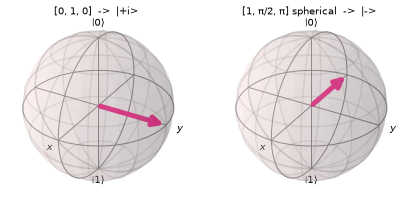

In [21]:
fig = plt.figure(figsize=(7, 3.4))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
plot_bloch_vector([0, 1, 0], title="[0, 1, 0]  ->  |+i>", ax=ax1)
plot_bloch_vector([1, np.pi / 2, np.pi], coord_type="spherical", title="[1, π/2, π] spherical  ->  |->", ax=ax2)
plt.show()

`plot_bloch_multivector(state)` draws one sphere per qubit, qubit 0 on the left (`reverse_bits=True` puts qubit n-1 first). Each arrow is the Bloch vector of that qubit's reduced state, obtained by tracing out all the other qubits. For a product state every arrow has length 1.

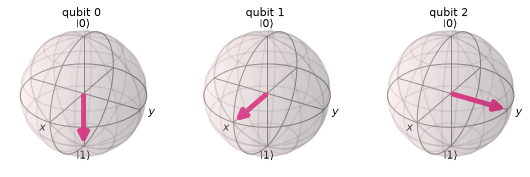

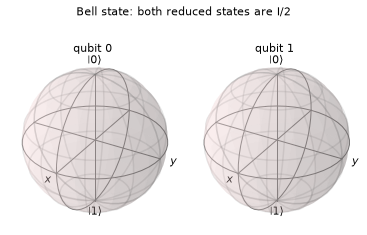

In [22]:
prod = QuantumCircuit(3)
prod.x(0)            # qubit 0: |1>  -> -z
prod.h(1)            # qubit 1: |+>  -> +x
prod.h(2)
prod.s(2)            # qubit 2: |+i> -> +y
display(plot_bloch_multivector(Statevector(prod), figsize=(2.6, 2.6), font_size=11))

plot_bloch_multivector(bell, figsize=(2.6, 2.6), font_size=11,
                       title="Bell state: both reduced states are I/2")

For a maximally entangled state such as a Bell or GHZ state, each reduced state is $I/2$, so `plot_bloch_multivector` shows no arrow (zero length). That is not a bug and not the state $|0\rangle$. A shorter-than-unit arrow means the qubit is entangled with others (or the state is mixed). Correlations between qubits never appear on the individual spheres.

### 2.3.4 The Q-sphere

`plot_state_qsphere` draws the whole n-qubit state on one sphere:

- one node per basis state with non-zero amplitude. $|0\dots0\rangle$ sits at the north pole, $|1\dots1\rangle$ at the south pole, and states with k ones sit on the k-th latitude ring (latitude = Hamming weight, not probability);
- node size (and line opacity) grows with the probability $|a_x|^2$;
- colour is the phase of the amplitude; read it against the colour wheel in the corner, or set `show_state_phases=True` to print it (`use_degrees=True` for degrees);
- the global phase is removed: the largest amplitude is rotated to phase 0, so $|\psi\rangle$ and $-|\psi\rangle$ look identical;
- for a mixed `DensityMatrix` it draws every eigenvector with eigenvalue above 0.001 on the same sphere, each normalised to full size, so the mixing weights are not visible: $0.7\,|00\rangle\langle 00| + 0.3\,|11\rangle\langle 11|$ shows two equally large nodes.

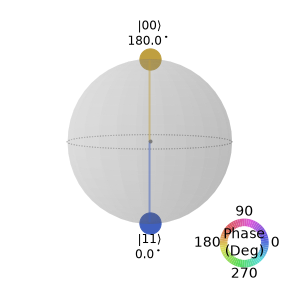

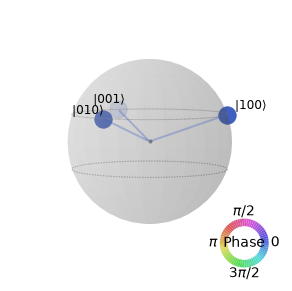

In [23]:
phi_minus_qc = QuantumCircuit(2)
phi_minus_qc.h(0)
phi_minus_qc.cx(0, 1)
phi_minus_qc.z(0)                           # (|00> - |11>)/sqrt(2)
phi_minus = Statevector(phi_minus_qc)
display(plot_state_qsphere(phi_minus, show_state_phases=True, use_degrees=True, figsize=(5, 5)))

w_state = Statevector(np.array([0, 1, 1, 0, 1, 0, 0, 0]) / np.sqrt(3))   # (|001> + |010> + |100>)/sqrt(3)
plot_state_qsphere(w_state, figsize=(5, 5))                            # three equal nodes on the weight-1 ring

To identify a state from a Q-sphere: (1) read the ket labels of the nodes, (2) compare node sizes for the probabilities, (3) compare colours or printed phases for relative phases. Two nodes with the same colour have the same phase; a phase of π between $|00\rangle$ and $|11\rangle$ tells $\Phi^-$ apart from $\Phi^+$.

### 2.3.5 City, Hinton and Pauli-vector plots

These three are built from the density matrix $\rho = |\psi\rangle\langle\psi|$.

- City (`plot_state_city`): two 3-D bar charts, $\mathrm{Re}\,\rho_{ij}$ and $\mathrm{Im}\,\rho_{ij}$. The diagonal holds the probabilities; the off-diagonal bars (coherences) carry the relative phases.
- Hinton (`plot_state_hinton`): the same two matrices as squares on a grey background. The square's area is proportional to $|\rho_{ij}|$, white means positive and black means negative.
- Pauli vector (`plot_state_paulivec`): one bar per Pauli string $P$ with value $\mathrm{Tr}(\rho P)$. Terms equal to zero are left out. Labels use Qiskit order, so the rightmost letter acts on qubit 0.

For the four Bell states the Pauli vector is $II = 1$ plus three signed correlators:

| State | $\langle XX\rangle$ | $\langle YY\rangle$ | $\langle ZZ\rangle$ |
|---|---|---|---|
| $\Phi^+ = (\lvert 00\rangle + \lvert 11\rangle)/\sqrt2$ | +1 | -1 | +1 |
| $\Phi^- = (\lvert 00\rangle - \lvert 11\rangle)/\sqrt2$ | -1 | +1 | +1 |
| $\Psi^+ = (\lvert 01\rangle + \lvert 10\rangle)/\sqrt2$ | +1 | +1 | -1 |
| $\Psi^- = (\lvert 01\rangle - \lvert 10\rangle)/\sqrt2$ | -1 | -1 | -1 |

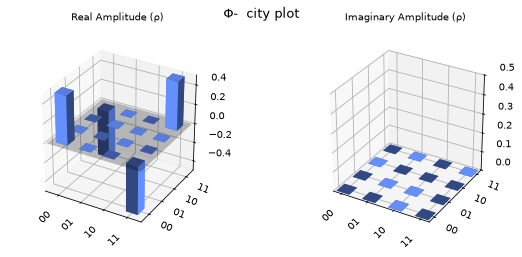

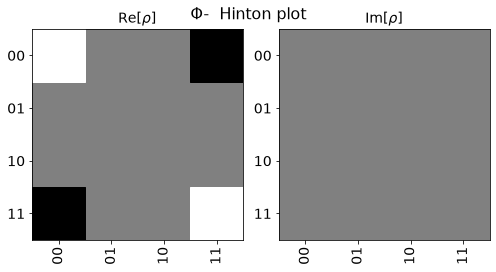

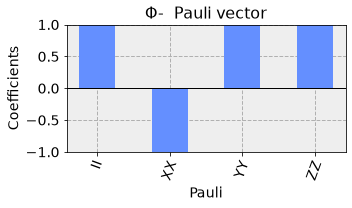

In [24]:
display(plot_state_city(phi_minus, title="Φ-  city plot", figsize=(8, 3.4)))
display(DensityMatrix(phi_minus).draw("hinton", title="Φ-  Hinton plot", figsize=(7, 3.8)))   # .draw forwards kwargs
plot_state_paulivec(phi_minus, title="Φ-  Pauli vector", figsize=(5, 3))

### 2.3.6 What no state plot shows: global phase

$|\psi\rangle$ and $e^{i\theta}|\psi\rangle$ are the same physical state, and all the plots above agree with that.

In [25]:
minus_bell = Statevector(-bell.data)                     # the same physical state, global phase π
print("bell == minus_bell   :", bell == minus_bell)      # False: different vectors
print("bell.equiv(minus_bell):", bell.equiv(minus_bell)) # True: equal up to global phase
print("same density matrix  :", DensityMatrix(bell) == DensityMatrix(minus_bell))

bell == minus_bell   : False
bell.equiv(minus_bell): True
same density matrix  : True


City, Hinton, Pauli-vector and Bloch plots are built from $\rho$, which has no global phase. The Q-sphere removes it explicitly. A relative phase, such as $\Phi^+$ versus $\Phi^-$, is visible in Q-sphere colours, in the off-diagonal elements of city and Hinton plots, and in the signs of the Pauli vector. It is not visible in a Z-basis measurement histogram or in `plot_bloch_multivector` of an entangled state.

### Practice 2.6 — From a Q-sphere to a circuit

Build `ex6_qc` (2 qubits, no measurements) whose state gives the Q-sphere below, up to a global phase. The two nodes are equally large and their phases differ by π.

Target Q-sphere:

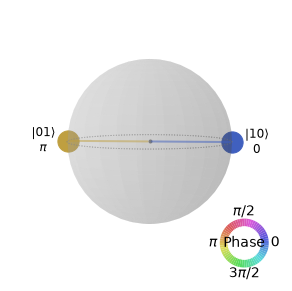

In [ ]:
ex6_qc = QuantumCircuit(2)
# TODO: add gates

plot_state_qsphere(Statevector(ex6_qc), show_state_phases=True, figsize=(5, 5))

In [ ]:
# Run this cell to check your answer
ex6_target = Statevector(np.array([0, 1, -1, 0]) / np.sqrt(2))       # (|01> - |10>)/sqrt(2)
assert ex6_qc.num_qubits == 2, "use 2 qubits"
assert ex6_qc.count_ops().get("measure", 0) == 0, "no measurements: Statevector(qc) needs a unitary circuit"
assert Statevector(ex6_qc).equiv(ex6_target), "not the state on the Q-sphere (check which kets appear and their relative phase)"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex6_qc = QuantumCircuit(2)
ex6_qc.h(0)
ex6_qc.x(1)
ex6_qc.cx(0, 1)      # (|01> + |10>)/sqrt(2)
ex6_qc.z(0)          # phase -1 on the |q1 q0> = |01> term -> (|10> - |01>)/sqrt(2)

plot_state_qsphere(Statevector(ex6_qc), show_state_phases=True, figsize=(5, 5))
```

The nodes are `|01>` and `|10>` (both on the equator, weight 1) with equal size, so the state is $(|01\rangle + e^{i\varphi}|10\rangle)/\sqrt2$, and the colours say $\varphi = \pi$. That is $\Psi^-$. Any circuit that prepares it up to a global phase passes, e.g. `x(0); x(1); h(0); cx(0, 1)` works too. Because the Q-sphere removes the global phase, $(|10\rangle - |01\rangle)/\sqrt2$ gives the same picture.

</details>

### Practice 2.7 — Bloch vectors from expectation values

> **Optional extension.** Practice 2.7: calculate Bloch vectors from Pauli expectations. You can skip this block, including its starter/check cells and solutions, and [continue with the core path](#s2-resume-88). Later core code does not require this block.

`plot_bloch_multivector` draws, for qubit k, the vector $(\langle X_k\rangle, \langle Y_k\rangle, \langle Z_k\rangle)$. For the state of `ex7_qc`, compute `ex7_vectors`: a list of three `[x, y, z]` lists, qubit 0 first, using `ex7_state.expectation_value(Pauli(label))`.

Pauli labels are little-endian too: $X$ on qubit 0 of a 3-qubit system is `Pauli("IIX")`. Predict the result before you run it.

In [ ]:
ex7_qc = QuantumCircuit(3)
ex7_qc.h(0)
ex7_qc.cx(0, 1)
ex7_qc.ry(np.pi / 3, 2)
ex7_state = Statevector(ex7_qc)

ex7_vectors = None   # TODO: [[<X0>, <Y0>, <Z0>], [<X1>, <Y1>, <Z1>], [<X2>, <Y2>, <Z2>]]

In [ ]:
# Run this cell to check your answer
ex7_ref = []
for k in range(3):
    rho_k = partial_trace(ex7_state, [j for j in range(3) if j != k])     # reduced state of qubit k
    ex7_ref.append([float(np.real(np.trace(rho_k.data @ Pauli(p).to_matrix()))) for p in "XYZ"])
assert ex7_vectors is not None and np.shape(ex7_vectors) == (3, 3), "three [x, y, z] lists, qubit 0 first"
assert np.allclose(ex7_vectors, ex7_ref, atol=1e-6), "compare your Pauli labels: 'IIX' acts on qubit 0"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex7_qc = QuantumCircuit(3)
ex7_qc.h(0)
ex7_qc.cx(0, 1)
ex7_qc.ry(np.pi / 3, 2)
ex7_state = Statevector(ex7_qc)

n = ex7_qc.num_qubits
ex7_vectors = []
for k in range(n):
    vec = []
    for p in "XYZ":
        label = ["I"] * n
        label[n - 1 - k] = p                  # rightmost character acts on qubit 0
        vec.append(float(np.real(ex7_state.expectation_value(Pauli("".join(label))))))
    ex7_vectors.append(vec)
print(np.round(ex7_vectors, 3))
plot_bloch_multivector(ex7_state, figsize=(2.4, 2.4), font_size=10)
```

Qubits 0 and 1 form a Bell pair, so each has $\langle X\rangle = \langle Y\rangle = \langle Z\rangle = 0$ and its arrow vanishes. Qubit 2 is $R_Y(\pi/3)|0\rangle$ with Bloch vector $(\sin\frac{\pi}{3}, 0, \cos\frac{\pi}{3}) = (0.866, 0, 0.5)$. If you put the Pauli letter in the leftmost position for qubit 0, you get the vectors of qubits 2 and 0 swapped.

</details>

<a id="s2-resume-88"></a>

Q2.8. Which figure is `plot_bloch_multivector(Statevector(qc))` for this circuit?

```python
qc = QuantumCircuit(2)
qc.h(0)
qc.s(0)
qc.x(1)
qc.h(1)
```

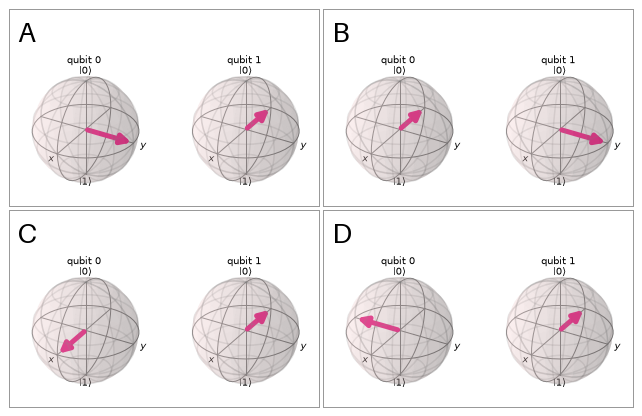

A. Figure A

B. Figure B

C. Figure C

D. Figure D

<details>
<summary>Show answer</summary>

Answer: A

Qubit 0: `h` then `s` gives $|{+i}\rangle$, an arrow along $+y$. Qubit 1: `x` then `h` gives $|-\rangle$, along $-x$. The spheres are titled `qubit 0`, `qubit 1` from the left. B swaps the two qubits, C leaves out the `s` (qubit 0 along $+x$), and D uses `sdg` (qubit 0 along $-y$).

</details>

Q2.9. Which two statements about `plot_state_qsphere` are correct? (Select two.)

A. The latitude of a node encodes the probability of that basis state.

B. The size of a node grows with the probability of that basis state.

C. Multiplying the state by $-1$ turns every node to the opposite colour.

D. The colour of a node encodes the phase of that basis state's amplitude.

E. For a Bell state the Q-sphere shows no nodes, because each qubit's reduced state is maximally mixed.

<details>
<summary>Show answer</summary>

Answer: B, D

Size tracks probability and colour tracks phase. Latitude is the Hamming weight (number of 1s), not the probability (A). The plot removes the global phase by rotating the largest amplitude to phase 0, so $-|\psi\rangle$ looks the same as $|\psi\rangle$ (C). E mixes the Q-sphere up with `plot_bloch_multivector`: the Q-sphere of a Bell state shows two equal nodes.

</details>

Q2.10. The city plot below shows a single-qubit state. Which circuit prepares it from $|0\rangle$?

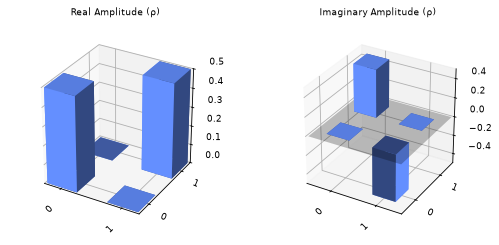

A. `qc.h(0)`

B. `qc.x(0); qc.h(0)`

C. `qc.h(0); qc.s(0)`

D. `qc.x(0)`

<details>
<summary>Show answer</summary>

Answer: C

The real part is diagonal with 0.5 on both entries (equal superposition, no real coherence), and the imaginary part has off-diagonal entries of $\mp 0.5$. That is $\rho = \frac12\begin{pmatrix}1 & -i\\ i & 1\end{pmatrix}$, the state $|{+i}\rangle$ from `h` then `s`. $|+\rangle$ (A) and $|-\rangle$ (B) have real off-diagonals of $+0.5$ and $-0.5$ and no imaginary part, and $|1\rangle$ (D) has a single real bar at $\rho_{11}=1$.

</details>

<a id="s2-core-95"></a>

## Section review — exam-style questions

First pass: answer the unmarked questions. Items labelled **Optional extension** or **Deeper API practice** are a separate second pass; they are not prerequisites for moving to the next notebook.

Answer each core question before opening its fold. Multi-select items say how many options to choose; there is no partial credit on the exam.

Q2.11. `qc` is a 3-qubit circuit with a barrier. Which call prints a text drawing with `q_2` as the top wire and no barrier?

A. `print(qc.draw(reverse_bits=True, plot_barriers=False))`

B. `print(qc.draw(wire_order="reverse", barriers=False))`

C. `qc.draw("mpl", reverse_bits=True, plot_barriers=False)`

D. `print(qc.draw(justify="right", plot_barriers=False))`

<details>
<summary>Show answer</summary>

Answer: A

`reverse_bits=True` puts the highest-index qubit on top and `plot_barriers=False` hides barriers; with no `output` the text drawer is used. B uses a keyword that does not exist (`barriers`), so `draw()` raises `TypeError` (and `wire_order` expects a list of indices). C returns a Matplotlib figure, not text. D only changes horizontal gate placement.

</details>

Q2.12. What does `fold=-1` do in `qc.draw("mpl", fold=-1)`?

A. It reverses the order of the wires.

B. It wraps the drawing after every single layer.

C. It switches folding off, so the whole circuit is drawn on one row.

D. It raises `ValueError`, because `fold` must be positive.

<details>
<summary>Show answer</summary>

Answer: C

`fold` sets where the drawing wraps (characters for text, layers for mpl; the mpl default is 25). `-1` disables wrapping. Reversing the wires is `reverse_bits` (A).

</details>

Q2.13. Which two values are valid for `output` in `Statevector.draw(output=...)`? (Select two.)

A. `"histogram"`

B. `"qsphere"`

C. `"mpl"`

D. `"bloch_vector"`

E. `"paulivec"`

<details>
<summary>Show answer</summary>

Answer: B, E

Valid keywords are `"repr"`, `"text"`, `"latex"`, `"latex_source"`, `"qsphere"`, `"hinton"`, `"bloch"`, `"city"` and `"paulivec"`. The others raise `ValueError`. `"mpl"` is a circuit-drawer output, and a histogram needs counts, not a state.

</details>

Q2.14. Which bitstring appears in the counts of this circuit?

```python
qc = QuantumCircuit(3, 3)
qc.x(0)
qc.measure([0, 1, 2], [2, 1, 0])
sampler = SamplerV2(mode=AerSimulator())
counts = sampler.run([qc], shots=100).result()[0].data.c.get_counts()
```

A. `'001'`

B. `'100'`

C. `'010'`

D. `'000'`

<details>
<summary>Show answer</summary>

Answer: B

Qubit 0 is 1 and is measured into classical bit 2, which is the leftmost character of the key `c2 c1 c0`. The key follows the classical bits, so the result is `'100'`. `'001'` is the answer for the usual `measure([0, 1, 2], [0, 1, 2])`.

</details>

Q2.15. Which histogram can this code produce?

```python
amps = np.array([0, 0.6, 0, 0, 0, 0, 0.8j, 0])
sv = Statevector(amps)
plot_histogram(sv.sample_counts(shots=1000))
```

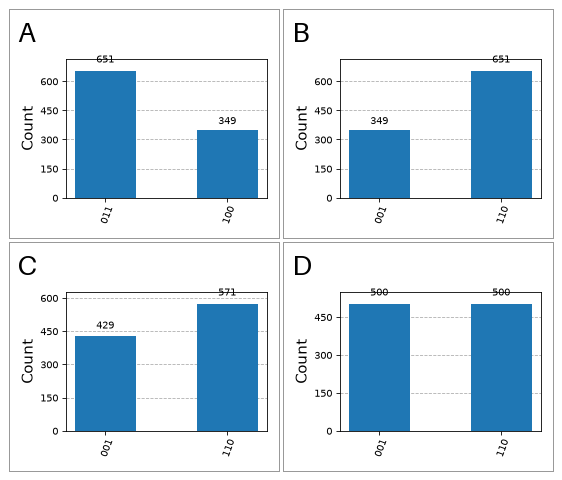

A. Histogram A

B. Histogram B

C. Histogram C

D. Histogram D

<details>
<summary>Show answer</summary>

Answer: B

Array index $k$ is the basis state whose bitstring is $k$ in binary with qubit 0 as the rightmost bit: index 1 is `001` and index 6 is `110`. The probabilities are $|0.6|^2 = 0.36$ and $|0.8i|^2 = 0.64$; the phase $i$ does not change them. A writes the bits in reverse order, C uses the amplitudes 0.6 : 0.8 without squaring, and D ignores the amplitudes altogether.

</details>

Q2.16. What happens with `plot_histogram(counts, sort="hamming")` when no `target_string` is given?

> **Deeper API practice — optional on the first pass.** The exact validation error for Hamming sorting is deeper plotting API practice.

A. The bars are sorted by the Hamming weight (number of 1s) of each bitstring.

B. The option is ignored and the default `"asc"` order is used.

C. The bars are sorted by count, largest first.

D. A `VisualizationError` is raised, because a distance sort needs `target_string`.

<details>
<summary>Show answer</summary>

Answer: D

`"hamming"` sorts by the Hamming distance from `target_string`, so the target is mandatory and Qiskit raises `VisualizationError: Must define target_string when using distance measure.` Sorting by count is `"value"` / `"value_desc"`.

</details>

Q2.17. Which circuit produces the Q-sphere below (phases printed with `show_state_phases=True`)?

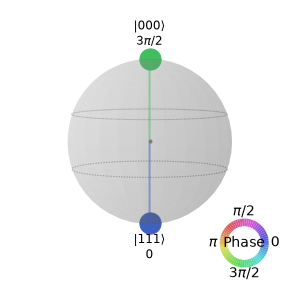

A.

```python
qc = QuantumCircuit(3)
qc.h(0); qc.cx(0, 1); qc.cx(0, 2)
qc.z(0)
```

B.

```python
qc = QuantumCircuit(3)
qc.h(0); qc.cx(0, 1); qc.cx(0, 2)
```

C.

```python
qc = QuantumCircuit(3)
qc.h(0); qc.cx(0, 1); qc.cx(0, 2)
qc.s(0)
```

D.

```python
qc = QuantumCircuit(3)
qc.h(0); qc.cx(0, 1); qc.cx(0, 2)
qc.sdg(0)
```

<details>
<summary>Show answer</summary>

Answer: C

Two equal nodes at the poles mean $(|000\rangle + e^{i\varphi}|111\rangle)/\sqrt2$, and the label says $\varphi = \pi/2$. After the GHZ preparation, `s(0)` multiplies every term with qubit 0 in $|1\rangle$ by $i$, which is only $|111\rangle$. `z` gives phase $\pi$ (A), no extra gate gives 0 (B), and `sdg` gives $3\pi/2$ (D).

</details>

Q2.18. The Pauli-vector plot below belongs to one of the four Bell states. Which one?

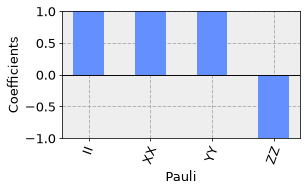

A. $\Psi^+ = (|01\rangle + |10\rangle)/\sqrt2$

B. $\Phi^+ = (|00\rangle + |11\rangle)/\sqrt2$

C. $\Phi^- = (|00\rangle - |11\rangle)/\sqrt2$

D. $\Psi^- = (|01\rangle - |10\rangle)/\sqrt2$

<details>
<summary>Show answer</summary>

Answer: A

The bars are $II=XX=YY=+1$ and $ZZ=-1$. $\langle ZZ\rangle = -1$ means the two bits always differ (a $\Psi$ state), and $\langle XX\rangle = +1$ picks the + sign. $\Phi^+$ has $(XX, YY, ZZ) = (+1, -1, +1)$, $\Phi^-$ has $(-1, +1, +1)$ and $\Psi^-$ has $(-1, -1, -1)$.

</details>

Q2.19. Which two visualizations cannot tell $\Phi^+ = (|00\rangle + |11\rangle)/\sqrt2$ apart from $\Phi^- = (|00\rangle - |11\rangle)/\sqrt2$? (Select two.)

A. `plot_state_qsphere` of each statevector

B. `plot_state_paulivec` of each statevector

C. `plot_bloch_multivector` of each statevector

D. `plot_state_city` of each statevector

E. `plot_histogram` of counts from measuring both qubits in the computational basis

<details>
<summary>Show answer</summary>

Answer: C, E

Both states give $P(00) = P(11) = 1/2$, so Z-basis counts look the same (E). Both have maximally mixed single-qubit reduced states, so every Bloch arrow has zero length (C). The relative phase shows up as a different node colour on the Q-sphere (A), as the sign of $\langle XX\rangle$ and $\langle YY\rangle$ in the Pauli vector (B), and as the sign of the off-diagonal bars $\rho_{00,11}$ in the city plot (D).

</details>

Q2.20. What is printed?

> **Deeper API practice — optional on the first pass.** Recognising decomposed gates is core; memorising this exact CX count is additional practice.

```python
qc = QuantumCircuit(3)
qc.ccx(0, 1, 2)
qc.swap(0, 1)
print(qc.decompose().count_ops()["cx"])
```

A. `0`

B. `3`

C. `6`

D. `9`

<details>
<summary>Show answer</summary>

Answer: D

`decompose()` expands every gate by one level: the Toffoli becomes 6 `cx` (plus `h`, `t`, `tdg`) and the `swap` becomes 3 `cx`, so 9. A would need `decompose()` to leave standard gates closed (and then `count_ops()["cx"]` would raise `KeyError` rather than print 0). B and C count only one of the two gates.

</details>

Q2.21. Which state does `plot_bloch_vector([1, np.pi / 2, np.pi / 2], coord_type="spherical")` show?

A. $|+\rangle$

B. $|{-i}\rangle$

C. $|1\rangle$

D. $|{+i}\rangle$

<details>
<summary>Show answer</summary>

Answer: D

Spherical coordinates are `[r, θ, φ]` with θ from $+z$ and φ from $+x$. $\theta = \pi/2$ puts the vector on the equator and $\varphi = \pi/2$ turns it to $+y$, so $(x, y, z) = (0, 1, 0)$, which is $|{+i}\rangle$. $\varphi = 0$ would give $|+\rangle$, and $\theta = \pi$ would give $|1\rangle$.

</details>

Q2.22. What does `plot_bloch_multivector` show for the Bell state $(|00\rangle + |11\rangle)/\sqrt2$?

A. Two arrows pointing along $+z$, one per qubit

B. One arrow along $+x$ and one along $-x$

C. Two spheres without a visible arrow, because each reduced state has Bloch vector $(0, 0, 0)$

D. An error, because entangled states cannot be split into single-qubit spheres

<details>
<summary>Show answer</summary>

Answer: C

Each sphere shows the reduced state of one qubit. For a Bell state that is $I/2$, so $\langle X\rangle = \langle Y\rangle = \langle Z\rangle = 0$ and the arrow has zero length. The function works for any state (D is wrong), it just cannot display correlations.

</details>

Q2.23. Which output does this code print?

```python
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
print(qc.draw(reverse_bits=True, initial_state=True))
```

A.

```text
        ┌───┐     
q_0: |0>┤ H ├──■──
        └───┘┌─┴─┐
q_1: |0>─────┤ X ├
             └───┘
```

B.

```text
             ┌───┐
q_1: |0>─────┤ X ├
        ┌───┐└─┬─┘
q_0: |0>┤ H ├──■──
        └───┘     
```

C.

```text
          ┌───┐
q_1: ─────┤ X ├
     ┌───┐└─┬─┘
q_0: ┤ H ├──■──
     └───┘     
```

D.

```text
             ┌───┐
q_0: |0>─────┤ X ├
        ┌───┐└─┬─┘
q_1: |0>┤ H ├──■──
        └───┘     
```

<details>
<summary>Show answer</summary>

Answer: B

`reverse_bits=True` puts `q_1` on top while the gates stay on their qubits: `H` on `q_0` (now the bottom wire) and the control on `q_0`. `initial_state=True` adds `|0>` to each wire. A is not reversed, C has no `|0>` labels, and D is a different circuit (the `H` and the control are on `q_1`).

</details>

## Cheat sheet

Use this as a reference. It includes optional APIs as well as the core workflow; it is not a list of details to memorise in one pass.

Circuit drawings

| Want | Use |
|---|---|
| ASCII drawing | `print(qc)`, `qc.draw()`, `qc.draw("text")` → `TextDrawing` |
| Matplotlib / LaTeX image / LaTeX code | `qc.draw("mpl")` → `Figure`; `"latex"` → PIL image; `"latex_source"` → `str` |
| Same thing as a function | `circuit_drawer(qc, output="mpl", ...)` |
| Save | `qc.draw("mpl", filename="qc.png")` |
| Highest qubit on top | `reverse_bits=True` |
| Hide barriers / initial-state labels | `plot_barriers=False` / `initial_state=True` |
| Wrapping | `fold=N` (text: characters, default 80 in Jupyter; mpl: layers, default 25); `fold=-1` off |
| Idle wires | `idle_wires=False` hides; default `"auto"` hides them only for circuits with a layout |
| Gate placement | `justify="left"` (default), `"right"`, `"none"` |
| One wire per clbit | `cregbundle=False` |
| Styles | `"iqp"` (default), `"iqp-dark"`, `"clifford"`, `"textbook"`, `"bw"`, a dict (`{"name": ..., key: value}`) or JSON; unknown dict keys are ignored |
| Look inside boxes | `qc.decompose()` (all, one level), `qc.decompose("name")`, `qc.decompose(reps=2)` |
| Transpiled circuit | labels `q_i -> p` (virtual → physical); `with_layout=False` for physical names only |
| Dynamic circuits | `If-0 / Else-0 / End-0`, `Switch-0 / Case-0`, `For-0`, `While-0`; the digit is the nesting depth; `c_0=0x1` bit condition, `0x3` register value |

Measurement plots

| Function / option | Remember |
|---|---|
| `plot_histogram(counts)` | integer counts, y label `Count`; float values are normalised |
| `plot_distribution(data)` | always normalised, y label `Quasi-probability`, default `figsize=(7, 5)` |
| list of dicts + `legend=[...]` | side-by-side comparison; legend length must match (`VisualizationError`) |
| `sort=` | `"asc"` (default), `"desc"`, `"value"`, `"value_desc"`, `"hamming"` + `target_string` |
| `number_to_keep=N` | N largest + one `rest` bar per dataset |
| `bar_labels=False`, `title=`, `color=`, `figsize=`, `ax=`, `filename=` | cosmetics |
| Bitstring order | `'c_{n-1} ... c_1 c_0'`: clbit 0 is the rightmost character |
| Register name in `pub_result.data.<name>` | `c` for `QuantumCircuit(n, n)`, `meas` for `measure_all()` |

State plots (`Statevector` / `DensityMatrix` / array input; `state.draw(key)` calls the same function)

| Key | Function | Read |
|---|---|---|
| `"bloch"` | `plot_bloch_multivector` | per-qubit $(\langle X\rangle,\langle Y\rangle,\langle Z\rangle)$, qubit 0 on the left; entangled → short or no arrow |
| – | `plot_bloch_vector(v, coord_type="cartesian"/"spherical")` | spherical `[r, θ, φ]`, θ from +z, φ from +x |
| `"qsphere"` | `plot_state_qsphere` | latitude = Hamming weight, size = probability, colour = phase; global phase removed |
| `"city"` | `plot_state_city` | 3-D bars of Re ρ and Im ρ |
| `"hinton"` | `plot_state_hinton` | squares for Re ρ and Im ρ: area = magnitude, white +, black − |
| `"paulivec"` | `plot_state_paulivec` | $\mathrm{Tr}(\rho P)$ per Pauli string, zeros omitted |
| `"repr"` (default), `"text"`, `"latex"`, `"latex_source"` | – | amplitudes; `"latex"` needs sympy |

Bloch cardinal states: $|0\rangle\,{+z}$, $|1\rangle\,{-z}$, $|+\rangle\,{+x}$, $|-\rangle\,{-x}$, $|{+i}\rangle\,{+y}$ (`h`,`s`), $|{-i}\rangle\,{-y}$ (`h`,`sdg`). Bell-state $(\langle XX\rangle,\langle YY\rangle,\langle ZZ\rangle)$: $\Phi^+ (+,-,+)$, $\Phi^- (-,+,+)$, $\Psi^+ (+,+,-)$, $\Psi^- (-,-,-)$. No state plot shows a global phase.

Device plots (need Graphviz): `plot_gate_map(backend)`, `plot_coupling_map(n, coords, edges)`, `plot_circuit_layout(isa_qc, backend, view="virtual" | "physical")`, `plot_error_map(backend)` (also seaborn).

## Sources and further reading

Qiskit Advocate KR study notebooks (Section 2), in [korean-community / 2026 Qiskit Advocate Qiskit 개발자 자격증 스터디 / Section_2_Visualize_Quantum_Circuits](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94/Section_2_Visualize_Quantum_Circuits):
- `1_Visualize_Quantum_Circuits.ipynb`
- `2_Visualize_Quantum_Measurements.ipynb`
- `3_Visualize_Quantum_States_ko.ipynb`

QAMP 2025 textbook: [kibrahim757/qiskit_2x_certification_exam_tutorial](https://github.com/kibrahim757/qiskit_2x_certification_exam_tutorial), folder `Section_2_Visualize_Quantum_Circuits`.

Official documentation (listed for this section in the exam syllabus)
- [Visualize circuits](https://quantum.cloud.ibm.com/docs/guides/visualize-circuits)
- [Visualize results](https://quantum.cloud.ibm.com/docs/guides/visualize-results)
- [Plot quantum states](https://quantum.cloud.ibm.com/docs/guides/plot-quantum-states)
- [`qiskit.visualization` API reference](https://quantum.cloud.ibm.com/docs/api/qiskit/visualization)

API pages used most here: [`QuantumCircuit.draw`](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.circuit.QuantumCircuit#draw), [`circuit_drawer`](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.visualization.circuit_drawer), [`plot_histogram`](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.visualization.plot_histogram), [`plot_distribution`](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.visualization.plot_distribution), [`plot_state_qsphere`](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.visualization.plot_state_qsphere), [`Statevector.draw`](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.quantum_info.Statevector#draw).

## References

Version checked: qiskit 2.0.3, qiskit-aer 0.17.1 and qiskit-ibm-runtime 0.40.1. Local runs use `SamplerV2` / `EstimatorV2` on `AerSimulator`.

- [IBM certification page / official objectives](https://www.ibm.com/training/certification/ibm-certified-quantum-computation-using-qiskit-v2x-developer-associate-C9008400)
- [IBM announcement for the v2.X certification](https://www.ibm.com/quantum/blog/qiskit-v2x-developer-certification)
- [Qiskit SDK 2.0 API index](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/index)
- [qiskit-ibm-runtime 0.39 API index](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40)
- [QuantumCircuit.draw (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/qiskit.circuit.QuantumCircuit)
- [Visualization module (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/visualization)
- [Statevector (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/qiskit.quantum_info.Statevector)
- [IBM guide: Visualize circuits](https://quantum.cloud.ibm.com/docs/guides/visualize-circuits)
- [IBM guide: Visualize results](https://quantum.cloud.ibm.com/docs/guides/visualize-results)

### Community repositories

- [Qiskit Advocate KR study repository](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94)
- [QAMP 2025 Qiskit 2.x certification tutorial](https://github.com/kibrahim757/qiskit_2x_certification_exam_tutorial)
